# 01 – First molecules: from SMILES to structures

**Goal:** parse three SMILES strings with RDKit, draw the structures, and calculate molecular formula, average MW and monoisotopic mass.

**Molecules:** β-D-glucose, (−)-menthol, (R)-(+)-limonene.

Run the cells top to bottom (**Shift + Enter**). All cells share one Python session, as in an R or MATLAB workspace, so later cells use variables defined in earlier ones.

## Step 1 – Imports

- `from rdkit import Chem` loads RDKit's core module (reading and writing molecules, plus the `Mol` object) and binds it to the name `Chem`.
- `from rdkit.Chem import Draw, Descriptors, rdMolDescriptors` loads three submodules: drawing, property calculation (MW, exact mass), and the molecular-formula function.

Compared with R: `library(pkg)` puts all of a package's functions directly into your search path. In Python, functions stay *namespaced*, so you call `Chem.MolFromSmiles(...)`, which is closer to R's `pkg::fun()`. MATLAB toolboxes have no direct equivalent: their functions are global once installed.

In [9]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, rdMolDescriptors

No output means the imports worked. A `ModuleNotFoundError` means the kernel isn't using the `chemml` environment (check the kernel name in the top-right corner).

## Step 2 – Store the SMILES in a dictionary

`smiles` is a **dict**, which maps keys (here, molecule names) to values (here, SMILES strings).

- In R, this is roughly a named list: `list("(-)-menthol" = "CC(C)...")`. In MATLAB, it's roughly a `struct` or `containers.Map`. Unlike a struct, a dict's keys can be any string, including ones with parentheses and hyphens.
- You access a value by key, not by position: `smiles["(-)-menthol"]`. Dicts keep insertion order (Python ≥ 3.7).
- Positional indexing applies to lists, and it is **0-based**: if `x = [10, 20, 30]`, then `x[0]` is `10`, and `x[-1]` is the last element.

SMILES stereo notation: `@` / `@@` mean the neighbours are listed anticlockwise or clockwise, viewed from the preceding atom. Ring closures use matching digits. Hydrogens are implicit.

In [10]:
smiles = {
    "beta-D-glucose": "OC[C@H]1O[C@@H](O)[C@H](O)[C@@H](O)[C@@H]1O",
    "(-)-menthol": "CC(C)[C@@H]1CC[C@@H](C)C[C@H]1O",
    "(R)-limonene": "CC1=CC[C@@H](CC1)C(=C)C",
}

smiles

{'beta-D-glucose': 'OC[C@H]1O[C@@H](O)[C@H](O)[C@@H](O)[C@@H]1O',
 '(-)-menthol': 'CC(C)[C@@H]1CC[C@@H](C)C[C@H]1O',
 '(R)-limonene': 'CC1=CC[C@@H](CC1)C(=C)C'}

A bare expression on the last line of a cell is displayed automatically. This works like typing a variable name at the R prompt, or omitting the semicolon in MATLAB. Only the *last* expression is shown. Use `print()` for anything earlier in the cell.

## Step 3 – Parse the SMILES into `Mol` objects

- `Chem.MolFromSmiles(smi)` returns an RDKit `Mol` object (atoms, bonds, rings, stereo) or `None` if the string is invalid. It doesn't raise an exception. It prints a "SMILES Parse Error" message and returns `None`, so check the return value.
- `smiles.items()` yields `(key, value)` pairs, and `for name, smi in ...` unpacks each pair into two variables. Python `for` loops iterate directly over items. The R equivalent is `for (name in names(smiles)) { smi <- smiles[[name]] }`, and in MATLAB you'd loop over an index, `for i = 1:numel(...)`. Python rarely needs an index loop.
- Blocks are defined by **indentation** (4 spaces) instead of `{ }` (R) or `end` (MATLAB). The indentation is part of the syntax, not just style.
- `mol is None` tests for "no value", like `is.null()` in R or `isempty()` in MATLAB. Use `is`, not `==`, for `None`.
- `mols = {}` creates an empty dict, and `mols[name] = mol` adds an entry.

In [11]:
mols = {}

for name, smi in smiles.items():
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        print(f"Could not parse {name}: {smi}")
    else:
        mols[name] = mol

print(f"Parsed {len(mols)} molecules")

Parsed 3 molecules


- `f"..."` is an f-string: expressions inside `{ }` are evaluated and inserted. It's equivalent to `sprintf()` in R or MATLAB, but inline.
- `len(mols)` gives the number of entries, like `length()` in R or `numel()` in MATLAB.

Expected output: `Parsed 3 molecules`.

## Step 4 – Draw the structures

`Draw.MolsToGridImage()` renders a list of `Mol` objects as a single image grid.

- `mols.values()` and `mols.keys()` return *views* of the dict. `list(...)` converts them to ordinary lists, which the function expects.
- `legends=`, `molsPerRow=` and `subImgSize=` are keyword arguments, as in R's `f(x, n = 3)`. MATLAB's closest equivalent is name–value pairs (`'Name', value`).
- `(300, 300)` is a **tuple**, an immutable sequence, used here for width × height in pixels.

Wedges and hashes come from the `@`/`@@` tags. Check them: (−)-menthol (1*R*,2*S*,5*R*) should show all three substituents in the all-*trans* (all-equatorial) arrangement, and β-D-glucose should have every ring substituent equatorial.

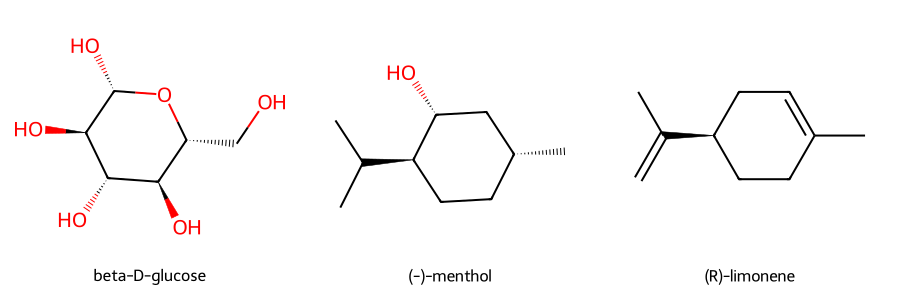

In [12]:
Draw.MolsToGridImage(
    list(mols.values()),
    legends=list(mols.keys()),
    molsPerRow=3,
    subImgSize=(300, 300),
)

## Step 5 – Formula and molecular weight

- `rdMolDescriptors.CalcMolFormula(mol)` gives the molecular formula as a string.
- `Descriptors.MolWt(mol)` gives the **average** MW from natural isotope abundances. Use it for stoichiometry.
- `Descriptors.ExactMolWt(mol)` gives the **monoisotopic** mass (¹²C, ¹H, ¹⁶O). Use it for HRMS comparison.

Format specifiers inside f-strings follow the same logic as `sprintf`:
- `{mw:>9.2f}` means right-aligned, width 9, 2 decimals. It's equivalent to `%9.2f`.
- `{name:<16}` means left-aligned, width 16. It's equivalent to `%-16s`.

The header line uses literal strings (`'Molecule'`) inside the braces so the column widths match the rows below.

In [13]:
print(f"{'Molecule':<16} {'Formula':<10} {'MW (avg)':>9} {'Exact mass':>11}")

for name, mol in mols.items():
    formula = rdMolDescriptors.CalcMolFormula(mol)
    mw = Descriptors.MolWt(mol)
    exact = Descriptors.ExactMolWt(mol)
    print(f"{name:<16} {formula:<10} {mw:>9.2f} {exact:>11.4f}")

Molecule         Formula     MW (avg)  Exact mass
beta-D-glucose   C6H12O6       180.16    180.0634
(-)-menthol      C10H20O       156.27    156.1514
(R)-limonene     C10H16        136.24    136.1252


Expected results:

| Molecule | Formula | MW |
|---|---|---|
| β-D-glucose | C6H12O6 | 180.16 |
| (−)-menthol | C10H20O | 156.27 |
| (R)-limonene | C10H16 | 136.24 |

Menthol and limonene are both C10 monoterpenes (two isoprene units).

## Exercises

Do these yourself. Ask for a hint if you're stuck, and send me your solution for review.

1. **Add a molecule.** Add (1R)-(+)-camphor (or another published terpene) to `smiles` and rerun Steps 2–5. Check the formula. (PubChem lists SMILES strings.)
2. **Invalid input.** Delete the final `1` from the glucose SMILES (an unclosed ring) and rerun Steps 2 and 3. What does RDKit print, and what ends up in `mols`? Then restore it.
3. **Stereochemistry.** Change one `@@` in the menthol SMILES to `@` and redraw. Which diastereomer is it? Does MW change, and why?
4. **HRMS.** Write one line that calculates the expected *m/z* of [M+Na]⁺ for menthol from `ExactMolWt` and the mass of Na⁺ (22.9892).

## Attempts

1. **Add a molecule.** Add (1R)-(+)-camphor (or another published terpene) to `smiles` and rerun Steps 2–5. Check the formula. (PubChem lists SMILES strings.)

In [17]:
#Exercise 1
smiles1 = {
    "beta-D-glucose": "OC[C@H]1O[C@@H](O)[C@H](O)[C@@H](O)[C@@H]1O",
    "(-)-menthol": "CC(C)[C@@H]1CC[C@@H](C)C[C@H]1O",
    "(R)-limonene": "CC1=CC[C@@H](CC1)C(=C)C",
    "(1R)-(+)-camphor": "CC1(C)[C@@H]2CC[C@@]1(C)C(=O)C2"
}

mols1 = {}

for name, smi in smiles1.items():
    mol1 = Chem.MolFromSmiles(smi)
    if mol1 is None:
        print(f"Could not parse {name}: {smi}")
    else:
        mols1[name] = mol1

print(f"Parsed {len(mols1)} molecules")

Draw.MolsToGridImage(
    list(mols1.values()),
    legends=list(mols1.keys()),
    molsPerRow=4,
    subImgSize=(300, 300),
)

camphor = mols1["(1R)-(+)-camphor"]
formula_camphor = rdMolDescriptors.CalcMolFormula(camphor)
MolWt_camphor = Descriptors.MolWt(camphor)

print (f"Camphor: {formula_camphor}, MW {MolWt_camphor:.2f}")

Parsed 4 molecules
Camphor: C10H16O, MW 152.24


2. **Invalid input.** Delete the final `1` from the glucose SMILES (an unclosed ring) and rerun Steps 2 and 3. What does RDKit print, and what ends up in `mols`? Then restore it.

RDKit prints:
"Could not parse beta-D-glucose: OC[C@H]1O[C@@H](O)[C@H](O)[C@@H](O)[C@@H]O
Parsed 2 molecules
[23:33:23] SMILES Parse Error: unclosed ring for input: 'OC[C@H]1O[C@@H](O)[C@H](O)[C@@H](O)[C@@H]O'"

mols then only has menthol and limonene, and glucose is missing. 

3. **Stereochemistry.** Change one `@@` in the menthol SMILES to `@` and redraw. Which diastereomer is it? Does MW change, and why?

I created the epimer isomenthol separately, MW stays the same because they have the same chemical formula.

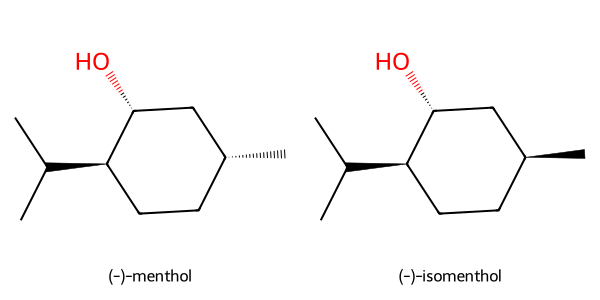

In [18]:
isomenthol = Chem.MolFromSmiles("CC(C)[C@@H]1CC[C@H](C)C[C@H]1O")

pair = {
    "(-)-menthol": mols["(-)-menthol"],
    "(-)-isomenthol": isomenthol,
}

Draw.MolsToGridImage(
    list(pair.values()),
    legends=list(pair.keys()),
    molsPerRow=2,
    subImgSize=(300, 300),
)

4. **HRMS.** Write one line that calculates the expected *m/z* of [M+Na]⁺ for menthol from `ExactMolWt` and the mass of Na⁺ (22.9892).

In [19]:
NA_PLUS_MASS = 22.9892
mz_na = Descriptors.ExactMolWt(mols["(-)-menthol"])+NA_PLUS_MASS

label = f"[{rdMolDescriptors.CalcMolFormula(mols["(-)-menthol"])}+Na]\u207a"

print(f"m/z for {label}: {mz_na:.4f}")


m/z for [C10H20O+Na]⁺: 179.1406
